# 05 · Audio processing, verification and handoff


<a id="SETUP"></a>
### `SETUP` · Setup: component environment and immutable evidence

In [1]:
# Code block: 13-SETUP
from pathlib import Path
import sys
WORKSPACE = next(p for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / 'source/bpdr_input').is_dir())
sys.path.insert(0, str(WORKSPACE / 'source'))
from bpdr_input.reporting.notebook_setup import prepare, load_catalogs, show
globals().update(prepare(WORKSPACE))
show(pd.DataFrame([{'check': 'Saved model and evidence identities', 'result': 'PASS',
                    'recorded_run': RUN.name}]))


,check,result,recorded_run
0,Saved model and evidence identities,PASS,b4c64c3b861a48c494c092458716b4fc


<a id="CONTEXT"></a>
### `CONTEXT` · Load local split catalogs and common helper names

In [2]:
# Code block: 13-CONTEXT
globals().update(load_catalogs(RUN, MANIFEST))
show(pd.DataFrame([
    dict(split=s, recordings=len(SOURCE_RECORDS[s]), singers=len(groups[s]),
         intervention_attempts=len(PAIRS[s])) for s in SPLITS
]))


,split,recordings,singers,intervention_attempts
0,train,16,8,64
1,calibration,4,2,16
2,pilot_evaluation,4,2,16


<a id="MODEL-LOAD-DEMO"></a>
### `MODEL-LOAD-DEMO` · Load the guarded saved diagnostic checkpoint

In [4]:
# MODEL-LOAD-DEMO
from bpdr_input.repair.learned_runtime import load_model as load_active_model
MODEL, PAYLOAD, DEMO_CARD = load_active_model()
ESTIMATOR = MODEL['estimator']
params = ESTIMATOR.get_params()
show(pd.DataFrame([{'parameter': k, 'saved_model_value': params[k]} for k in ['n_estimators', 'max_depth', 'min_samples_leaf', 'criterion', 'bootstrap', 'max_features', 'random_state', 'n_jobs']]))

,parameter,saved_model_value
0,n_estimators,96
1,max_depth,8
2,min_samples_leaf,12
3,criterion,squared_error
4,bootstrap,False
5,max_features,1.0000
6,random_state,339
7,n_jobs,2


<a id="MODEL-LOAD-DEMO-3"></a>
#### Prepare or verify the next result

In [5]:
# Code block: MODEL-LOAD-DEMO-3
print('Saved model type:', PAYLOAD['model_type'])
print('Saved operating settings:', PAYLOAD['operating_policy'])
print('Active notebook-trained checkpoint:', DEMO_CARD['checkpoint'])
print('Checkpoint SHA-256:', DEMO_CARD['checkpoint_sha256'])
print('Loading this diagnostic checkpoint does not assert that research gates passed.')

Saved model type: extra_trees
Saved operating settings: {'gain': 1.0, 'deadband_cents': 3.0}
Active notebook-trained checkpoint: C:\Users\lnipu\Projects\Music Rp\RP\J26-DS-339\experiments\bpdr_input\BPDR_Workspace\results\model_recovery\notebook_training\2759404560ab4b559a633659d316bec0\selected_model.joblib
Checkpoint SHA-256: 682f8e4839b80fa032a52769d6186ca349937e638ef4ddfd8bdf85278a3ec9b3
Loading this diagnostic checkpoint does not assert that research gates passed.


<a id="PILOT-RESULTS"></a>
### `PILOT-RESULTS` · Full delivered table including all attempted cases

In [7]:
# Code block: PILOT-RESULTS
VERIFICATION_PATH = RUN / 'rendered_verification.json'
VERIFIED = read_json(VERIFICATION_PATH)

result_rows = []
for recorded, pair in zip(VERIFIED['shifts'], PAIRS['pilot_evaluation']):
    row = dict(singer=recorded['singer'], vowel=pair['source']['vowel'], injected_cents=pair['cents'])
    if 'excluded' in recorded:
        row.update(outcome='unscorable', reason=recorded['excluded'], input_local_MAE=None, output_local_MAE=None, improved=False)
    else:
        row.update(outcome=recorded['outcome'], reason='improved' if recorded['verified_improvement'] else 'no demonstrated target improvement', input_local_MAE=recorded['input_mae_cents'], output_local_MAE=recorded['output_mae_cents'], improved=recorded['verified_improvement'])
    result_rows.append(row)
ALL_RESULTS = pd.DataFrame(result_rows)
show(ALL_RESULTS.round(4))

,singer,vowel,injected_cents,outcome,reason,input_local_MAE,output_local_MAE,improved
0,female6,a,-30.0000,unscorable,NO_OWN_AUDIO_STABLE_RUN_WITH_CONTEXT_FOR_096_SECOND_INTERVENTION,—,—,False
1,female6,a,-20.0000,unscorable,NO_OWN_AUDIO_STABLE_RUN_WITH_CONTEXT_FOR_096_SECOND_INTERVENTION,—,—,False
2,female6,a,20.0000,unscorable,NO_OWN_AUDIO_STABLE_RUN_WITH_CONTEXT_FOR_096_SECOND_INTERVENTION,—,—,False
3,female6,a,30.0000,unscorable,NO_OWN_AUDIO_STABLE_RUN_WITH_CONTEXT_FOR_096_SECOND_INTERVENTION,—,—,False
4,female6,e,-30.0000,unscorable,CONTROLLED_INTERVENTION_AUDIT_FAILED,—,—,False
5,female6,e,-20.0000,unscorable,CONTROLLED_INTERVENTION_AUDIT_FAILED,—,—,False
6,female6,e,20.0000,unscorable,CONTROLLED_INTERVENTION_AUDIT_FAILED,—,—,False
7,female6,e,30.0000,unscorable,CONTROLLED_INTERVENTION_AUDIT_FAILED,—,—,False
8,male6,a,-30.0000,VERIFIED_FIXTURE_CANDIDATE,no demonstrated target improvement,30.8083,30.8083,False
9,male6,a,-20.0000,unscorable,CONTROLLED_INTERVENTION_AUDIT_FAILED,—,—,False


<a id="PILOT-RESULTS-2"></a>
#### Inspect the result

In [15]:
# Code block: PILOT-RESULTS-2
VALID = [r for r in VERIFIED['shifts'] if 'excluded' not in r]
assert len(VALID) == 4 and all((r['missing_output_scored_frames'] == 0 for r in VALID))
input_mean = float(np.mean([r['input_mae_cents'] for r in VALID]))
output_mean = float(np.mean([r['output_mae_cents'] for r in VALID]))
improvement = 1 - output_mean / input_mean
np.testing.assert_allclose([input_mean, output_mean, improvement], [CARD['metrics']['input_mae_cents'], CARD['metrics']['output_mae_cents'], CARD['metrics']['error_reduction_fraction']])
original_rows = []
for r in VERIFIED['originals']:
    a, sr = sf.read(r['input'], dtype='float32')
    b, br = sf.read(r['output'], dtype='float32')
    assert r['preserved'] and sr == br and np.array_equal(a, b)
    original_rows.append(dict(singer=r['singer'], file=Path(r['input']).parent.name, outcome=r['outcome'], exact_working_samples_preserved=True))
show(pd.DataFrame(original_rows))

,singer,file,outcome,exact_working_samples_preserved
0,female6,00,IDENTITY,True
1,female6,01,WITHHELD,True
2,male6,02,WITHHELD,True
3,male6,03,WITHHELD,True


<a id="PILOT-RESULTS-3"></a>
#### Inspect the result

In [16]:
# Code block: PILOT-RESULTS-3
show(pd.DataFrame(VERIFIED['by_singer']).T)

,attempted,audited,delivered_previews,verified_improvements,input_mae_cents,output_mae_cents,error_reduction_fraction
female6,8.0000,0.0000,0.0000,0.0000,—,—,—
male6,8.0000,4.0000,3.0000,2.0000,27.4419,14.6630,0.4657


<a id="PILOT-RESULTS-4"></a>
#### Inspect the result

In [17]:
# Code block: PILOT-RESULTS-4
stages = pd.DataFrame([dict(stage='Raw predicted correction vs known target', baseline_MAE=EVIDENCE['outer']['zero_mae'], MAE=EVIDENCE['outer']['raw_correction_mae']), dict(stage='Permitted curve vs known target; withholds included', baseline_MAE=EVIDENCE['outer']['zero_mae'], MAE=EVIDENCE['outer']['permitted_correction_mae']), dict(stage='Actual WAV vs measured original; fixed local frames', baseline_MAE=input_mean, MAE=output_mean)])
show(stages.round(4))

,stage,baseline_MAE,MAE
0,Raw predicted correction vs known target,27.5000,6.0270
1,Permitted curve vs known target; withholds included,27.5000,14.6643
2,Actual WAV vs measured original; fixed local frames,27.4419,14.6630


<a id="PILOT-RESULTS-5"></a>
#### Prepare or verify the next result

In [18]:
# Code block: PILOT-RESULTS-5
print('The known intervention target and the realized measured pitch shift are close but not identical. Keep stage and reference definitions attached to each MAE.')
counts = [12, 1, 1, 2]
names = ['Unscorable intervention creation', 'Audited but withheld', 'Preview without target improvement', 'Verified local improvement']
assert sum(counts) == 16

The known intervention target and the realized measured pitch shift are close but not identical. Keep stage and reference definitions attached to each MAE.


<a id="PILOT-RESULTS-6"></a>
#### Visualize the result

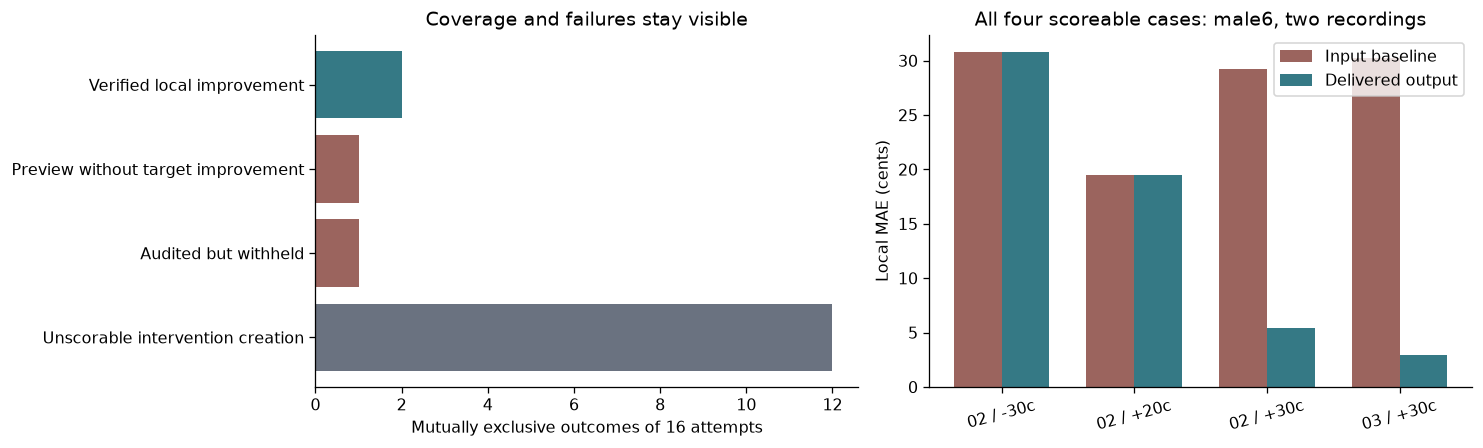

In [19]:
# PILOT-RESULTS-6
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].barh(names, counts, color=[COLORS['neutral'], COLORS['input'], COLORS['input'], COLORS['output']])
axes[0].set(xlabel='Mutually exclusive outcomes of 16 attempts', title='Coverage and failures stay visible')
x = np.arange(4)
axes[1].bar(x - 0.18, [r['input_mae_cents'] for r in VALID], 0.36, label='Input baseline', color=COLORS['input'])
axes[1].bar(x + 0.18, [r['output_mae_cents'] for r in VALID], 0.36, label='Delivered output', color=COLORS['output'])
axes[1].set_xticks(x, [f"{Path(r['input']).parent.name} / {r['cents']:+g}c" for r in VALID], rotation=15)
axes[1].set(ylabel='Local MAE (cents)', title='All four scoreable cases: male6, two recordings')
axes[1].legend()
plt.tight_layout()
plt.show()

 Keep all 16 attempts visible: 12 unscorable, four scoreable from one singer, three verified previews and two local improvements. Delivered MAE includes retained input when withheld. The 46.6% reduction is conditional on those four cases.

<a id="PILOT-DETAILS"></a>
### `PILOT-DETAILS` · Locations, predictions, permission and outcomes for all 16 attempts

In [12]:
# Code block: PILOT-DETAILS
detailed = []
for pair, result in zip(PAIRS['pilot_evaluation'], VERIFIED['shifts']):
    row = dict(singer=pair['source']['singer_id'], vowel=pair['source']['vowel'], shift_cents=pair['cents'], original_recording=Path(pair['source']['path']).name, intervention_seconds=str(pair.get('support_seconds')), scoreable='excluded' not in pair, exclusion=pair.get('excluded'))
    if 'excluded' not in pair:
        report = read_json(Path(result['directory']) / 'model_report.json')
        with np.load(result['target_path']) as z:
            fixed = z['mask'].astype(bool) & (z['target'] != 0)
        with np.load(Path(result['directory']) / 'model_predictions.npz') as z:
            raw_prediction = z['predictions'][0]
        row.update(outcome=result['outcome'], requested_intervals=str(report['permission']['intervals_seconds']), operating_mean_on_target_cents=float(raw_prediction[fixed].mean()), input_MAE=result['input_mae_cents'], delivered_MAE=result['output_mae_cents'], improved=result['verified_improvement'], permission_reasons=str(result['controller_reasons']), candidate_numerically_verified=result['delivered_preview'])
    detailed.append(row)
assert len(detailed) == 16
show(pd.DataFrame(detailed)[['singer', 'vowel', 'shift_cents', 'scoreable', 'exclusion', 'outcome', 'input_MAE', 'delivered_MAE', 'improved']].round(4))

,singer,vowel,shift_cents,scoreable,exclusion,outcome,input_MAE,delivered_MAE,improved
0,female6,a,-30.0000,False,NO_OWN_AUDIO_STABLE_RUN_WITH_CONTEXT_FOR_096_SECOND_INTERVENTION,—,—,—,—
1,female6,a,-20.0000,False,NO_OWN_AUDIO_STABLE_RUN_WITH_CONTEXT_FOR_096_SECOND_INTERVENTION,—,—,—,—
2,female6,a,20.0000,False,NO_OWN_AUDIO_STABLE_RUN_WITH_CONTEXT_FOR_096_SECOND_INTERVENTION,—,—,—,—
3,female6,a,30.0000,False,NO_OWN_AUDIO_STABLE_RUN_WITH_CONTEXT_FOR_096_SECOND_INTERVENTION,—,—,—,—
4,female6,e,-30.0000,False,CONTROLLED_INTERVENTION_AUDIT_FAILED,—,—,—,—
5,female6,e,-20.0000,False,CONTROLLED_INTERVENTION_AUDIT_FAILED,—,—,—,—
6,female6,e,20.0000,False,CONTROLLED_INTERVENTION_AUDIT_FAILED,—,—,—,—
7,female6,e,30.0000,False,CONTROLLED_INTERVENTION_AUDIT_FAILED,—,—,—,—
8,male6,a,-30.0000,True,—,VERIFIED_FIXTURE_CANDIDATE,30.8083,30.8083,False
9,male6,a,-20.0000,False,CONTROLLED_INTERVENTION_AUDIT_FAILED,—,—,—,—


<a id="PILOT-DETAILS-2"></a>
#### Prepare or verify the next result

In [13]:
# Code block: PILOT-DETAILS-2
print('Prediction is the stored operating curve on fixed target frames. Delivered MAE is measured from actual audio; unscorable rows have no invented score.')

Prediction is the stored operating curve on fixed target frames. Delivered MAE is measured from actual audio; unscorable rows have no invented score.


**Read the output.** Every attempt retains its singer, shift and exclusion/outcome. Unscorable attempts have no invented error score. Numerical preview validity and target-region improvement are separate.

<a id="DEMO-RUN"></a>
### `DEMO-RUN` · Live saved-weight audio-only inference (bounded local work)

In [21]:
# Code block: DEMO-RUN
from bpdr_input.repair.learned_runtime import run as learned_inference, load_model as load_demo_model
from bpdr_input.repair.demo_runtime import selected_output
MODEL, PAYLOAD, DEMO_CARD = load_demo_model()
ESTIMATOR = MODEL['estimator']
ACTIVE_CHECKPOINT = Path(DEMO_CARD['checkpoint'])

ACTIVE_VERIFICATION = read_json(ACTIVE_CHECKPOINT.parent / 'rendered_verification.json')
SELECTED = next(r for r in ACTIVE_VERIFICATION['shifts'] if r.get('verified_improvement'))
SELECTED_PAIR = next(p for p in PAIRS['pilot_evaluation'] if p.get('path_C') == SELECTED['input'])
before_model_sha, before_evidence_sha = sha(CHECKPOINT), sha(RUN / 'evidence.json')
FRESH_DIRECTORY, FRESH_REPORT = learned_inference(SELECTED['input'], output_root=WORKSPACE / 'results/notebook_inference')

FRESH_OUTPUT, output_label = selected_output(FRESH_REPORT)

INPUT_AUDIO, input_sr = sf.read(FRESH_REPORT['handoff']['accepted_audio']['path'], dtype='float32')
OUTPUT_AUDIO, output_sr = sf.read(FRESH_OUTPUT, dtype='float32')
REFERENCE_AUDIO, ref_sr = sf.read(SELECTED['reference'], dtype='float32')



<a id="DEMO-RUN-2"></a>
#### Inspect the result

In [22]:
# Code block: DEMO-RUN-2
with np.load(SELECTED['target_path']) as z:
    SCORE_TIMES = z['times']
    FIXED_MASK = z['mask'].astype(bool) & (z['target'] != 0)
reference_pitch = fine_pitch(REFERENCE_AUDIO, ref_sr, SCORE_TIMES)
fresh_input_error = fine_pitch(INPUT_AUDIO, input_sr, SCORE_TIMES) - reference_pitch
fresh_output_error = fine_pitch(OUTPUT_AUDIO, output_sr, SCORE_TIMES) - reference_pitch
assert np.isfinite(fresh_input_error[FIXED_MASK]).all() and np.isfinite(fresh_output_error[FIXED_MASK]).all()
FRESH_INPUT_MAE = float(np.abs(fresh_input_error[FIXED_MASK]).mean())
FRESH_OUTPUT_MAE = float(np.abs(fresh_output_error[FIXED_MASK]).mean())
np.testing.assert_allclose([FRESH_INPUT_MAE, FRESH_OUTPUT_MAE], [SELECTED['input_mae_cents'], SELECTED['output_mae_cents']], atol=0.01)
show(pd.DataFrame([dict(input_local_MAE_cents=FRESH_INPUT_MAE, output_local_MAE_cents=FRESH_OUTPUT_MAE, local_error_reduction_percent=100 * (1 - FRESH_OUTPUT_MAE / FRESH_INPUT_MAE), scored_frames=int(FIXED_MASK.sum()), full_recording_seconds=len(INPUT_AUDIO) / input_sr, outcome=FRESH_REPORT['outcome'])]).round(4))

,input_local_MAE_cents,output_local_MAE_cents,local_error_reduction_percent,scored_frames,full_recording_seconds,outcome
0,29.2022,5.4249,81.4230,36,13.9195,VERIFIED_FIXTURE_CANDIDATE


<a id="DEMO-RUN-3"></a>
#### Prepare or verify the next result

In [23]:
# Code block: DEMO-RUN-3
print('Fresh run folder:', FRESH_DIRECTORY)
print('Fresh delivered WAV:', FRESH_OUTPUT)
print('Clean reference and private mask were used only AFTER the runtime call.')
show(pd.DataFrame([dict(active_model_checkpoint=str(ACTIVE_CHECKPOINT), used_checkpoint_sha256=FRESH_REPORT['model_sha256'], source='Notebook 04 fit → saved file → guarded loader → this output')]))

Fresh run folder: C:\Users\lnipu\Projects\Music Rp\RP\J26-DS-339\experiments\bpdr_input\BPDR_Workspace\results\notebook_inference\bac87b19fd8b459ea0f4e5926a8fb0da
Fresh delivered WAV: C:\Users\lnipu\Projects\Music Rp\RP\J26-DS-339\experiments\bpdr_input\BPDR_Workspace\results\notebook_inference\bac87b19fd8b459ea0f4e5926a8fb0da\experimental_learned_candidate.wav
Clean reference and private mask were used only AFTER the runtime call.


,active_model_checkpoint,used_checkpoint_sha256,source
0,C:\Users\lnipu\Projects\Music Rp\RP\J26-DS-339\experiments\bpdr_input\BPDR_Workspace\results\model_recovery\notebook_training\2759404560ab4b559a633659d316bec0\selected_model.joblib,682f8e4839b80fa032a52769d6186ca349937e638ef4ddfd8bdf85278a3ec9b3,Notebook 04 fit → saved file → guarded loader → this output


 This is fresh audio-only inference using the model trained and saved in notebook 04. Its active checkpoint path/hash is checked against the runtime report. The chosen listening example is selected after development replay; read all attempts alongside it.

<a id="TREE-PREDICTION"></a>
### `TREE-PREDICTION` · Actual tree path and mean of 96 predictions

In [24]:
# TREE-PREDICTION
from bpdr_input.modeling.recovery_model import propose
with np.load(FRESH_DIRECTORY / 'features.npz') as z:
    FRESH_FEATURES = {k: z[k] for k in z.files}
fine_input = fine_pitch(INPUT_AUDIO, input_sr, FRESH_FEATURES['times_seconds'])
FRESH_VIEWS, FRESH_RELIABLE, FRESH_PROTECTED, FRESH_ADAPTER = runtime_views(FRESH_FEATURES, fine_input)
X_FRESH = context_features(FRESH_VIEWS[0], include_boundary=False)
proposal = propose(FRESH_VIEWS, MODEL, PAYLOAD)
with np.load(FRESH_DIRECTORY / 'model_predictions.npz') as z:
    np.testing.assert_allclose(z['predictions'], proposal['operating_predictions'], atol=1e-06)
    REQUESTED_CURVE = z['proposed_correction'].copy()
frame = int(np.flatnonzero(FIXED_MASK)[int(FIXED_MASK.sum()) // 2])
tree_outputs = np.array([tree.predict(X_FRESH[frame:frame + 1])[0] for tree in ESTIMATOR.estimators_])
forest_output = float(ESTIMATOR.predict(X_FRESH[frame:frame + 1])[0])
np.testing.assert_allclose(tree_outputs.mean(), forest_output)
show(pd.DataFrame([dict(frame=frame, time_seconds=SCORE_TIMES[frame], first_tree_cents=tree_outputs[0], mean_of_96_trees_cents=forest_output, operating_gain=PAYLOAD['operating_policy']['gain'], final_requested_cents=REQUESTED_CURVE[frame])]).round(5))

,frame,time_seconds,first_tree_cents,mean_of_96_trees_cents,operating_gain,final_requested_cents
0,623,12.4600,-24.1738,-23.3218,1.0000,-23.3218


<a id="TREE-PREDICTION-2"></a>
#### Inspect the result

In [25]:
# Code block: TREE-PREDICTION-2
tree = ESTIMATOR.estimators_[0]
node = 0
path_rows = []
while tree.tree_.feature[node] >= 0:
    column = int(tree.tree_.feature[node])
    threshold = float(tree.tree_.threshold[node])
    value = float(X_FRESH[frame, column])
    left = value <= threshold
    path_rows.append(dict(node=node, feature=FEATURE_NAMES[column], observed_scaled_value=value, question=f'<= {threshold:.5f}', answer=bool(left)))
    node = int(tree.tree_.children_left[node] if left else tree.tree_.children_right[node])
show(pd.DataFrame(path_rows))

,node,feature,observed_scaled_value,question,answer
0,0,residual_sine,0.7903,<= -0.02749,False
1,126,pitch_minus_median_121,0.3712,<= 0.23343,False
2,186,residual_spread_11,0.0645,<= 0.17236,True
3,187,residual_mean_61,0.9349,<= 0.07090,False
4,201,residual_mean_31,1.1997,<= 0.55069,False
5,217,residual_spread_61,0.4683,<= 0.36970,False
6,221,residual_mean_61,0.9349,<= 0.77913,False


<a id="TREE-PREDICTION-3"></a>
#### Prepare or verify the next result

In [26]:
# Code block: TREE-PREDICTION-3
print('Reached leaf:', node, '; learned correction:', float(tree.tree_.value[node].ravel()[0]), 'cents; training rows reaching leaf:', int(tree.tree_.n_node_samples[node]))

Reached leaf: 225 ; learned correction: -24.173764906303237 cents; training rows reaching leaf: 16


<a id="TREE-PREDICTION-4"></a>
#### Visualize the result

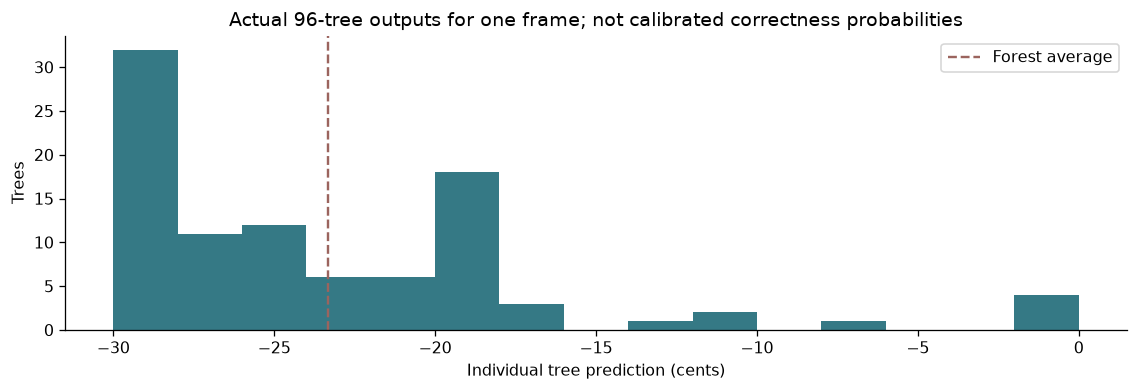

In [27]:
#  TREE-PREDICTION-4
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.hist(tree_outputs, bins=15, color=COLORS['output'])
ax.axvline(forest_output, color=COLORS['input'], linestyle='--', label='Forest average')
ax.set(xlabel='Individual tree prediction (cents)', ylabel='Trees', title='Actual 96-tree outputs for one frame; not calibrated correctness probabilities')
ax.legend()
plt.tight_layout()
plt.show()

 One fitted tree follows feature thresholds; the forest averages 96 predictions. Tree spread is not a calibrated correctness probability. The inspected frame is selected after inference for explanation.

<a id="s17"></a>
## Permission, rendering, remeasurement and the final audible WAV

The controller can reject a predicted curve for excessive correction (>30 cents), changed-boundary disagreement (>5 cents), unreliable voicing, protected transitions, insufficient continuous support (<0.86 seconds), or too much affected audio (>25%). It does not silently clip an over-limit prediction into a pass. The largest above-deadband contiguous proposal is considered; short fragmented suggestions can therefore be withheld.

A permitted request is rendered using a pinned Praat/Parselmouth pitch tier. Measured frequencies are scaled by `2 ** (correction_cents / 1200)`, with local crossfades. The duration tier is unchanged. Samples outside the permitted support are copied exactly. The renderer is separate from both the frozen pitch analyzer and the learned tree model.

The result is checked for sample grid, clipping, realized pitch movement, direction, coverage and outside drift. It is then encoded as PCM24, reloaded from the exact saved WAV, and audited again. A failure retains the original. These are numerical safeguards, not independent musical approval.

Listen at the same volume. The shift is small and local; most of the full recording should sound unchanged. The reference is the original performed vocal, not a perfected or independently annotated intended melody.

<a id="RENDER-AUDIT"></a>
### `RENDER-AUDIT` · Exact encoded-WAV audit and three audio players

In [21]:
# Code block: RENDER-AUDIT
plan = FRESH_REPORT['permission']
transaction = FRESH_REPORT['transaction']
delivered = transaction['delivered_wav_audit']
audit = delivered['acoustic_audit']
assert plan['permitted'] and delivered['passed'] and audit['passed']
assert delivered['sha256'] == sha(FRESH_OUTPUT) and delivered['outside_support_unchanged']
inside = np.zeros(len(INPUT_AUDIO), dtype=bool)
sample_times = np.arange(len(INPUT_AUDIO)) / input_sr
for left, right in plan['intervals_seconds']:
    inside |= (sample_times >= left) & (sample_times < right)
assert np.array_equal(INPUT_AUDIO[~inside], OUTPUT_AUDIO[~inside])
show(pd.DataFrame([dict(check='Controller magnitude limit', observed=plan['requested_max_abs_cents'], limit=plan['policy']['max_correction_cents']), dict(check='Affected sample fraction', observed=plan['affected_fraction'], limit=plan['policy']['max_affected_fraction']), dict(check='Delivered fine-pitch median movement error', observed=audit['fine']['median_error_cents'], limit=audit['base_limits']['median_error_tolerance_cents']), dict(check='Delivered fine-pitch p90 movement error', observed=audit['fine']['p90_error_cents'], limit=audit['base_limits']['p90_error_tolerance_cents'])]))

,check,observed,limit
0,Controller magnitude limit,26.4485,30.0000
1,Affected sample fraction,0.0762,0.2500
2,Delivered fine-pitch median movement error,0.4393,5.0000
3,Delivered fine-pitch p90 movement error,1.2336,10.0000


<a id="RENDER-AUDIT-2"></a>
#### Prepare or verify the next result

In [22]:
# Code block: RENDER-AUDIT-2
print('Permitted intervals (seconds):', plan['intervals_seconds'])
print('Encoded subtype:', delivered['subtype'], '; sample count:', delivered['sample_count'])
print('Outside-support samples exactly unchanged:', bool(np.array_equal(INPUT_AUDIO[~inside], OUTPUT_AUDIO[~inside])))

Permitted intervals (seconds): [(11.94, 13.0)]
Encoded subtype: PCM_24 ; sample count: 306926
Outside-support samples exactly unchanged: True


<a id="RENDER-AUDIT-3"></a>
#### Visualize the result

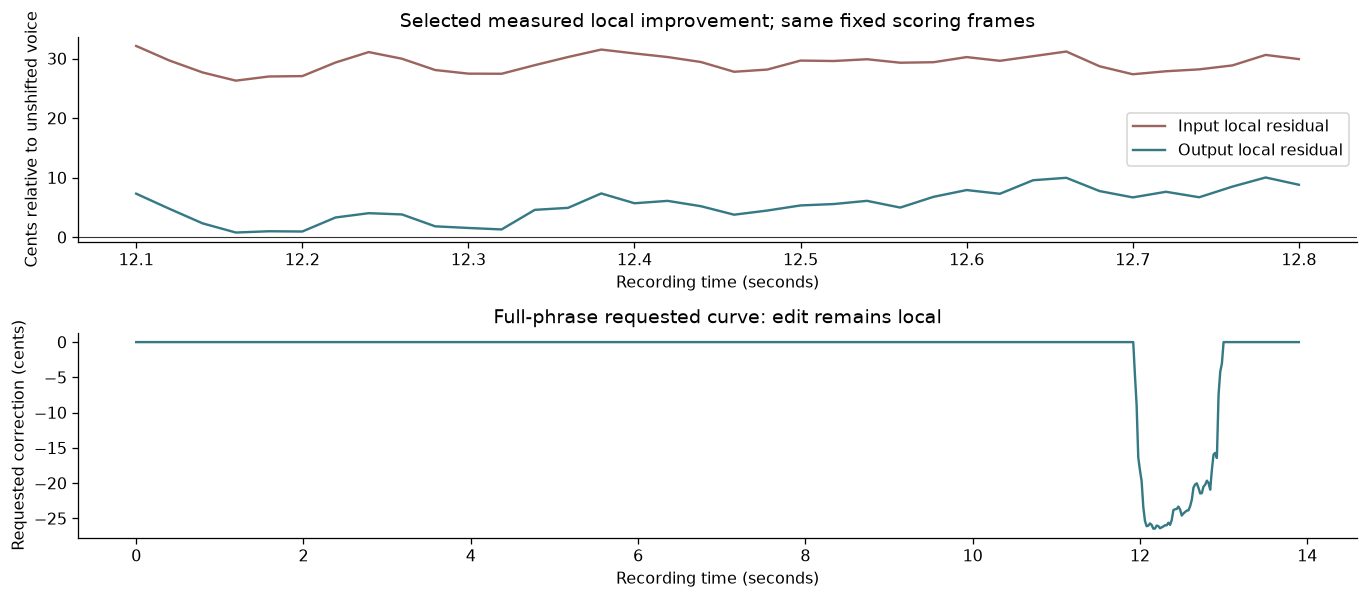

In [23]:
# RENDER-AUDIT-3
fig, axes = plt.subplots(2, 1, figsize=(12, 5.3))
axes[0].plot(SCORE_TIMES[FIXED_MASK], fresh_input_error[FIXED_MASK], color=COLORS['input'], label='Input local residual')
axes[0].plot(SCORE_TIMES[FIXED_MASK], fresh_output_error[FIXED_MASK], color=COLORS['output'], label='Output local residual')
axes[0].axhline(0, color='#333333', linewidth=0.7)
axes[0].set(xlabel='Recording time (seconds)', ylabel='Cents relative to unshifted voice', title='Selected measured local improvement; same fixed scoring frames')
axes[0].legend()
axes[1].plot(FRESH_FEATURES['times_seconds'], REQUESTED_CURVE, color=COLORS['output'])
axes[1].set(xlabel='Recording time (seconds)', ylabel='Requested correction (cents)', title='Full-phrase requested curve: edit remains local')
plt.tight_layout()
plt.show()

<a id="RENDER-AUDIT-4"></a>
#### Listen to the example

In [24]:
# RENDER-AUDIT-4
for label, wave in [('Input: real voice with a known added +30-cent shift', INPUT_AUDIO), ('Actual fresh learned-model output', OUTPUT_AUDIO), ('Original unshifted performance: evaluation reference only', REFERENCE_AUDIO)]:
    show(Markdown('**' + label + '**'))
    show(Audio(wave, rate=input_sr, normalize=False))

**Input: real voice with a known added +30-cent shift**

**Actual fresh learned-model output**

**Original unshifted performance: evaluation reference only**

 The exact encoded WAV is remeasured and samples outside permitted support are checked unchanged. Listen to input, preview and unshifted reference at matched volume. Requested-movement validity is not independent musical approval.

<a id="CONTROLLER-FIXTURES"></a>
### `CONTROLLER-FIXTURES` · Permitted, withheld and rollback examples using actual controller code

In [25]:
# Code block: CONTROLLER-FIXTURES
from bpdr_input.repair.repair_controller import plan_fixture, transact_fixture, FixturePolicy
from bpdr_input.repair.framewise_renderer import RendererPolicy
show(pd.DataFrame([asdict(FixturePolicy()), asdict(RendererPolicy())]))

,version,max_correction_cents,max_disagreement_cents,max_uncertainty_cents,max_affected_fraction,min_support_seconds,parselmouth_version,time_step_seconds,pitch_floor_hz,pitch_ceiling_hz,ramp_seconds,max_cents
0,controller-fixture-0.1,30.0000,5.0000,5.0000,0.2500,0.8600,—,—,—,—,—,—
1,praat-framewise-candidate-0.1,—,—,—,—,0.8600,0.4.7,0.0100,50.0000,1500.0000,0.0800,30.0000


<a id="CONTROLLER-FIXTURES-2"></a>
#### Inspect the result

In [37]:
# CONTROLLER-FIXTURES-2
fixture_sr = 22050
fixture_audio = (0.1 * np.sin(2 * np.pi * 220 * np.arange(4 * fixture_sr) / fixture_sr)).astype(np.float32)
fixture_times = np.arange(len(fixture_audio) // 441 + 1) * 0.02
curve = np.where((fixture_times >= 1) & (fixture_times < 1.9), -20.0, 0.0)
reliable = np.ones(len(curve), bool)
protected = np.zeros(len(curve), bool)
trials = []
for label, requested, protection in [('Supported local edit', curve, protected), ('Over 30-cent limit', curve * 2, protected), ('Too short', np.where((fixture_times >= 1) & (fixture_times < 1.2), -20.0, 0.0), protected), ('Too much coverage', np.where(fixture_times < 2.0, -20.0, 0.0), protected), ('Protected transition', curve, (fixture_times >= 1) & (fixture_times < 1.1))]:
    plan_fixture_result = plan_fixture(fixture_audio, fixture_sr, fixture_times, requested, requested, np.zeros(len(curve)), reliable, protection)
    trials.append(dict(illustrative_fixture=label, permitted=plan_fixture_result['permitted'], reasons=str(plan_fixture_result['reasons'])))
assert trials[0]['permitted'] and (not any((r['permitted'] for r in trials[1:])))
show(pd.DataFrame(trials))

,illustrative_fixture,permitted,reasons
0,Supported local edit,True,[]
1,Over 30-cent limit,False,['CORRECTION_LIMIT']
2,Too short,False,['INSUFFICIENT_SUPPORT']
3,Too much coverage,False,['AFFECTED_FRACTION_LIMIT']
4,Protected transition,False,['PROTECTED_REGION']


In [27]:
# Code block: CONTROLLER-FIXTURES-3
permitted = plan_fixture(fixture_audio, fixture_sr, fixture_times, curve, curve, np.zeros(len(curve)), reliable, protected)
rolled_back, diagnostic = transact_fixture(fixture_audio, fixture_sr, permitted, lambda audio, *args: audio[:-1], lambda *args: {'passed': True})
assert diagnostic['rollback'] and np.array_equal(rolled_back, fixture_audio)
print('Deliberately invalid sample-count renderer ->', diagnostic['outcome'], '; original preserved exactly.')
print('These are numerical fixtures, not model performance or participant audio.')

Deliberately invalid sample-count renderer -> ROLLED_BACK ; original preserved exactly.
These are numerical fixtures, not model performance or participant audio.


 These constructed cases test permission and rollback mechanics. Over-limit, short, broad or protected proposals are withheld; an invalid renderer restores the original. They are not participant outcomes.

<a id="AUDIO-FAILURES"></a>
### `AUDIO-FAILURES` · Non-beneficial preview and withheld real-voice case

In [39]:
# Code block: AUDIO-FAILURES
failure = next((r for r in VALID if r['cents'] == -30.0))
withheld = next((r for r in VALID if r['outcome'] == 'WITHHELD'))
show(pd.DataFrame([failure, withheld])[['cents', 'outcome', 'input_mae_cents', 'output_mae_cents', 'verified_improvement', 'controller_reasons']])

,cents,outcome,input_mae_cents,output_mae_cents,verified_improvement,controller_reasons
0,-30.0000,VERIFIED_FIXTURE_CANDIDATE,30.8083,30.8083,False,[]
1,20.0000,WITHHELD,19.5138,19.5138,False,['INSUFFICIENT_SUPPORT']


<a id="AUDIO-FAILURES-2"></a>
#### Inspect the result

In [40]:
# Code block: AUDIO-FAILURES-2
show(Markdown('**Real controlled -30-cent input: a numerical preview did not improve its target region**'))

**Real controlled -30-cent input: a numerical preview did not improve its target region**

<a id="AUDIO-FAILURES-3"></a>
#### Listen to the example

In [41]:
# Code block: AUDIO-FAILURES-3
show(Audio(filename=failure['input'], normalize=False))
show(Markdown('**Recorded non-beneficial preview: movement validity is not target improvement**'))

**Recorded non-beneficial preview: movement validity is not target improvement**

<a id="AUDIO-FAILURES-4"></a>
#### Listen to the example

In [31]:
# Code block: AUDIO-FAILURES-4
show(Audio(filename=failure['output'], normalize=False))
x, sr = sf.read(withheld['input'], dtype='float32')
y, yr = sf.read(withheld['output'], dtype='float32')
assert sr == yr and np.array_equal(x, y)
print('Withheld case delivered the unchanged input. This is not counted as a successful correction.')
print('No harmful-edit rate is inferred without independent musical/quality judgments.')

Withheld case delivered the unchanged input. This is not counted as a successful correction.
No harmful-edit rate is inferred without independent musical/quality judgments.


A numerically valid edit can fail to improve the target region. A withheld case retains the input and is not counted as successful correction. No independently judged harmful-edit rate is available.

<a id="HANDOFF-CONTRACT"></a>
## Accepted-only output contract



<a id="HANDOFF-REJECTION"></a>
### `HANDOFF-REJECTION` · Rejected packages cannot contain or expose accepted audio

In [42]:
# Code block: HANDOFF-REJECTION
from bpdr_input.audio.contracts import ProcessingResult, Status, require_accepted_audio, AcceptedAudio
rejection = ProcessingResult('fixture', 'coded_source', Status.RERECORD_REQUIRED, reason_codes=('INSUFFICIENT_MELODIC_EVIDENCE',))
try:
    require_accepted_audio(rejection)
except ValueError as exc:
    print('Expected downstream block:', exc)
else:
    raise AssertionError('Rejected package exposed accepted audio')
print('Successful handoff validation also verifies file bytes, sample metadata and package-local path before extraction.')

Expected downstream block: Downstream processing blocked: RERECORD_REQUIRED
Successful handoff validation also verifies file bytes, sample metadata and package-local path before extraction.


 A rejected result must not expose accepted audio downstream. This fixture tests the contract; it is not a human suitability judgment.

In [45]:
# Code block: HANDOFF-REVIEW
from bpdr_input.audio.usability import UsabilityPolicy
from bpdr_input.repair.demo_review import review, export_reviewed
ACOUSTIC_REVIEW = review(FRESH_DIRECTORY, FRESH_REPORT, 'singing_humming_chant')
show(pd.DataFrame([asdict(UsabilityPolicy())]).T.rename(columns={0: 'provisional_setting'}))

,provisional_setting
version,provisional-melodic-evidence-demo-0.1
minimum_confidence,0.8000
maximum_tracker_disagreement_cents,50.0000
minimum_reliable_seconds,0.2000
minimum_contiguous_reliable_seconds,0.1200
minimum_agreeing_fraction_of_primary_voiced,0.5000
scope,Fixed unvalidated demo engineering settings; no musical approval


<a id="HANDOFF-REVIEW-3"></a>
#### Inspect the result

In [47]:
# Code block: HANDOFF-REVIEW-3
assert ACOUSTIC_REVIEW['preview']['decision'] == 'PASS_EVIDENCE'
PACKAGE_DIRECTORY, PACKAGE = export_reviewed(FRESH_DIRECTORY, FRESH_REPORT, ACOUSTIC_REVIEW, use_preview=True, confirmed=True, confirmation_kind='automated_test_fixture')
PACKAGE_DIAGNOSTICS = read_json(PACKAGE_DIRECTORY / 'diagnostics.json')
assert PACKAGE['status'] == 'ACCEPT_PREPARED'
assert not PACKAGE_DIAGNOSTICS['user_confirmed'] and (not PACKAGE_DIAGNOSTICS['research_approval'])
assert sha(PACKAGE_DIRECTORY / 'accepted.wav') == sha(FRESH_OUTPUT) == PACKAGE['accepted_audio']['checksum']
show(pd.DataFrame([dict(status=PACKAGE['status'], policy=PACKAGE['policy_version'], exact_candidate_bytes_exported=True, human_listening_performed=False, research_approval=False, output_waveform_sha256=PACKAGE['accepted_audio']['checksum'])]))

,status,policy,exact_candidate_bytes_exported,human_listening_performed,research_approval,output_waveform_sha256
0,ACCEPT_PREPARED,demo-user-reviewed-0.1,True,False,False,12c57ef84c8db1e59c8501b815415966deb529600c1381bad5ae1b2c645a042b


<a id="HANDOFF-REVIEW-4"></a>
#### Prepare or verify the next result

In [48]:
# Code block: HANDOFF-REVIEW-4
print('Notebook integration-fixture package:', PACKAGE_DIRECTORY)
import zipfile
with zipfile.ZipFile(PACKAGE_DIRECTORY / 'accepted_package.zip') as package_zip:
    assert set(package_zip.namelist()) == {'accepted.wav', 'handoff.json', 'diagnostics.json'}
    print('Downloadable package contents:', package_zip.namelist())

Notebook integration-fixture package: C:\Users\lnipu\Projects\Music Rp\RP\J26-DS-339\experiments\bpdr_input\BPDR_Workspace\results\notebook_inference\bac87b19fd8b459ea0f4e5926a8fb0da\reviewed_handoffs\b5498cfd0fae4e37994185910968796b
Downloadable package contents: ['accepted.wav', 'handoff.json', 'diagnostics.json']


 The notebook uses automated_test_fixture confirmation. The package verifies exact candidate bytes and contents; it does not claim human listening, user confirmation or research approval.

<a id="HANDOFF-EXTRACTOR"></a>
### `HANDOFF-EXTRACTOR` · Verify exact accepted WAV and saved GAME CSV/MIDI

In [50]:
# Code block: HANDOFF-EXTRACTOR
EXTRACTION_LINK = read_json(WORKSPACE / 'results/model_recovery/learned_extractor_fixture_current.json')
EXTRACTION = read_json(EXTRACTION_LINK['receipt'])
assert EXTRACTION['success'] and EXTRACTION['returncode'] == 0
assert EXTRACTION['accepted_sha256'] == sha(FRESH_OUTPUT)
original_fixture = Path(EXTRACTION_LINK['handoff_directory'])
assert sha(original_fixture / 'accepted.wav') == EXTRACTION['accepted_sha256']
assert read_json(original_fixture / 'diagnostics.json')['confirmation_kind'] == 'automated_test_fixture'
for item in EXTRACTION['artifacts']:
    assert sha(item['path']) == item['sha256']
csv_path = next((Path(r['path']) for r in EXTRACTION['artifacts'] if Path(r['path']).suffix == '.csv'))
midi_path = next((Path(r['path']) for r in EXTRACTION['artifacts'] if Path(r['path']).suffix == '.mid'))
EVENTS = pd.read_csv(csv_path)
assert {'onset', 'offset', 'pitch'} <= set(EVENTS.columns)
assert np.isfinite(EVENTS[['onset', 'offset', 'pitch']].to_numpy()).all()
assert (EVENTS.offset > EVENTS.onset).all()
show(EVENTS)

,onset,offset,pitch
0,1.2800,3.9400,47.9460
1,5.4300,8.9400,60.1270
2,10.1200,13.3600,65.1410


<a id="HANDOFF-EXTRACTOR-2"></a>
#### Prepare or verify the next result

In [51]:
# Code block: HANDOFF-EXTRACTOR-2
print('Exact prepared WAV -> GAME success:', EXTRACTION['success'])
print('Recorded extractor seconds:', EXTRACTION['elapsed_seconds'])
print('CSV:', csv_path)
print('MIDI:', midi_path)
print('GAME checkpoint SHA-256:', EXTRACTION['model_sha256'])
print('These pitch numbers are estimated MIDI-unit pitches, including fractions; they are not human ground truth.')

Exact prepared WAV -> GAME success: True
Recorded extractor seconds: 41.361
CSV: C:\Users\lnipu\Projects\Music Rp\RP\J26-DS-339\experiments\bpdr_input\BPDR_Workspace\results\demo_sessions\effdca937a1045ea99fc37130b94c83e\reviewed_handoffs\234bf4acbaab4841a678eb4357e16218\extraction_attempts\2f670b3ea12d410692256267c7859fc4\game_notes\accepted.csv
MIDI: C:\Users\lnipu\Projects\Music Rp\RP\J26-DS-339\experiments\bpdr_input\BPDR_Workspace\results\demo_sessions\effdca937a1045ea99fc37130b94c83e\reviewed_handoffs\234bf4acbaab4841a678eb4357e16218\extraction_attempts\2f670b3ea12d410692256267c7859fc4\game_notes\accepted.mid
GAME checkpoint SHA-256: e9904159fb0646e1a352b9d2bc74615547cfa3e32d45c7464d440ac142846d93
These pitch numbers are estimated MIDI-unit pitches, including fractions; they are not human ground truth.


<a id="HANDOFF-EXTRACTOR-3"></a>
#### Visualize the result

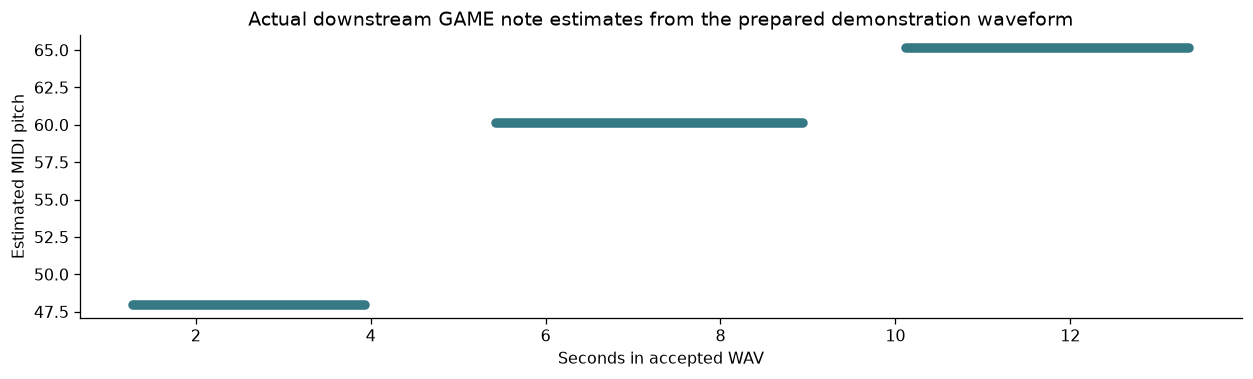

In [52]:
# Code block: HANDOFF-EXTRACTOR-3
fig, ax = plt.subplots(figsize=(11, 3.4))
for row in EVENTS.itertuples():
    ax.plot([row.onset, row.offset], [row.pitch, row.pitch], linewidth=6, solid_capstyle='round', color=COLORS['output'])
ax.set(xlabel='Seconds in accepted WAV', ylabel='Estimated MIDI pitch', title='Actual downstream GAME note estimates from the prepared demonstration waveform')
plt.tight_layout()
plt.show()

**Read the output.** The verified accepted WAV produced actual GAME CSV/MIDI artifacts. Estimated pitches are not human ground truth. Successful interface execution does not establish extraction accuracy or harmony integration.

<a id="HANDOFF-MIDI"></a>
### `HANDOFF-MIDI` · Parse MIDI and check serialized note timing against its CSV

In [53]:
# Code block: HANDOFF-MIDI
import mido
midi = mido.MidiFile(midi_path)
elapsed = 0.0
active = {}
midi_notes = []
for message in midi:
    elapsed += message.time
    if message.type == 'note_on' and message.velocity > 0:
        key = (message.channel, message.note)
        assert key not in active
        active[key] = elapsed
    elif message.type == 'note_off' or (message.type == 'note_on' and message.velocity == 0):
        key = (message.channel, message.note)
        assert key in active
        midi_notes.append(dict(onset=active.pop(key), offset=elapsed, pitch=message.note))
assert not active and len(midi_notes) == len(EVENTS)
midi_notes = sorted(midi_notes, key=lambda r: r['onset'])
np.testing.assert_allclose([[r['onset'], r['offset']] for r in midi_notes], EVENTS[['onset', 'offset']].to_numpy(), atol=0.02)
assert all((0 <= r['onset'] < r['offset'] <= len(OUTPUT_AUDIO) / output_sr + 0.02 for r in midi_notes))

<a id="HANDOFF-MIDI-2"></a>
#### Inspect the result

In [54]:
# Code block: HANDOFF-MIDI-2
show(pd.DataFrame(midi_notes))

,onset,offset,pitch
0,1.2802,3.9396,48
1,5.4302,8.9396,60
2,10.1198,13.3604,65


<a id="HANDOFF-MIDI-3"></a>
#### Prepare or verify the next result

In [42]:
# Code block: HANDOFF-MIDI-3
print('MIDI is parseable, balanced and aligned with its CSV within the declared 20-ms serialization tolerance.')
print('MIDI pitches are quantized; neither file is an independent musical reference or proof of extraction improvement.')

MIDI is parseable, balanced and aligned with its CSV within the declared 20-ms serialization tolerance.
MIDI pitches are quantized; neither file is an independent musical reference or proof of extraction improvement.


 Balanced note events and CSV timing agreement establish serialization consistency within 20 ms. Quantized MIDI notes are not an independent musical reference.